In [ ]:
# Laboratorio 17: Arboles de decisiones
# Alumno: YO
# Matricula: 20243L601050

In [1]:
import pandas as pd
import numpy as np

In [2]:
#Librerías de machine learning
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
# Metricas para algoritmos de clasificación
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [4]:
#Librería para graficar
import matplotlib.pyplot as plt

In [6]:
# 2. Cargar el dataset
# Daatset de Iris.
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['especie'] = iris.target
df['especie'] = df['especie'].map({0: 'setosa', 1:'versicolor', 2:'virginica'})
print ("Dimensiones del dataset: ", df.shape)
df.sample(2)

Dimensiones del dataset:  (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),especie
66,5.6,3.0,4.5,1.5,versicolor
80,5.5,2.4,3.8,1.1,versicolor


In [ ]:
# 3. Revisión de los datos / Preprocesamiento (ETL)
# Paso básico antes de entrenar los algortimos

In [7]:
# Distribución  de las clases
df['especie'].value_counts()

especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [8]:
# Verificar si hay valores nulos
print ("Valores nulos por columnas: ")
print (df.isnull().sum())

Valores nulos por columnas: 
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
especie              0
dtype: int64


In [ ]:
# 5. Selección de las variables predictoras y variable objetivo

In [9]:
# Variables predictoras
X = df[iris.feature_names]
# Variable objetivo
y = df['especie']

In [10]:
X.head(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2


In [11]:
print(y)

0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
         ...    
145    virginica
146    virginica
147    virginica
148    virginica
149    virginica
Name: especie, Length: 150, dtype: str


In [ ]:
# 6. División de los datos

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [14]:
print("Entrenamiento: ", X_train.shape)
print("Entrenameinto: ",y_train.shape)

Entrenamiento:  (120, 4)
Entrenameinto:  (120,)


In [16]:
print("Prueba: ", X_test.shape)
print("Prueba: ", y_test.shape)

Prueba:  (30, 4)
Prueba:  (30,)


In [ ]:
# 7. Entrenamiento de los datos
# Con el algoritmo Desicion Tree ("Arboles de desición"), debemos limitar la profundidad máxima (max_depth) para evitar el sobreajuste (memorizar) y facilitar la visualización del árbol.

In [27]:
#Creamos el modelo
modelo = DecisionTreeClassifier(
    criterion='gini', # Gini es el criterio más usado, tomando la variable mas importante
    max_depth=3, # Profundidad, se toman 3 criterios de división
    random_state=42
)

In [28]:
# Entrenamos el modelo
modelo.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

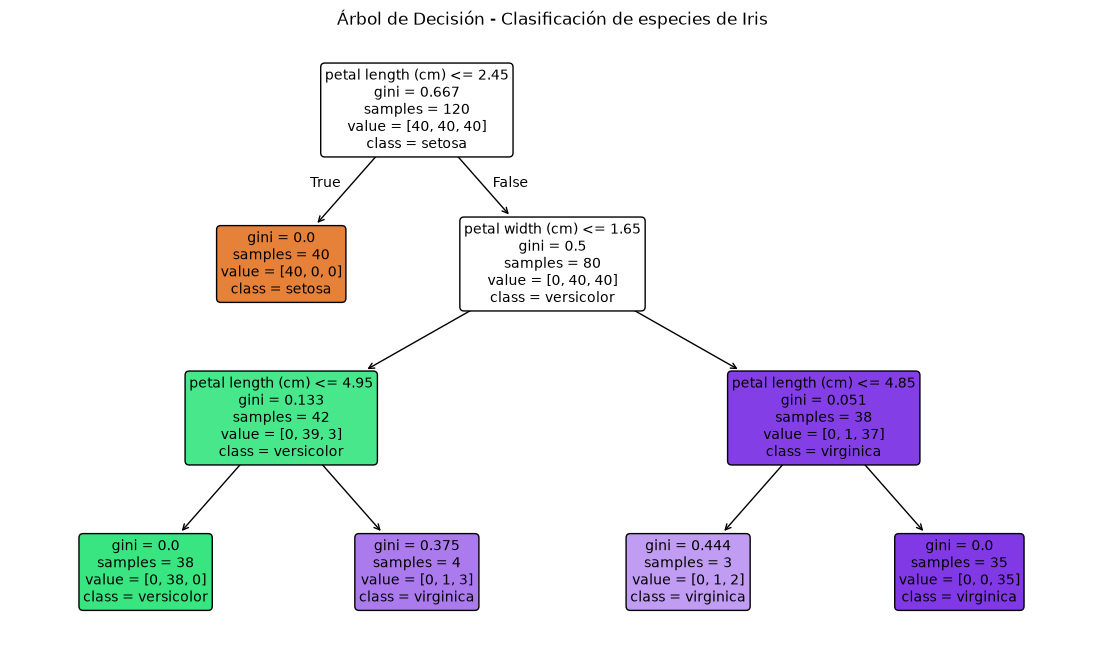

In [29]:
# Visualización del árbol de decisión
plt.figure(figsize=(14,8))
plot_tree(
    modelo,
    feature_names= iris.feature_names,
    class_names= modelo.classes_,
    filled = True,
    rounded = True,
    fontsize = 10
)
plt.title("Árbol de Decisión - Clasificación de especies de Iris")
plt.show()

In [ ]:
# 8. Evaluación del algoritmo
# Permite evaluar el desempeño del algoritmo sobre los datos de prueba.
# Accuary -> Exactitud
# Reorite de clasificación ( precisión, recall, f1-score)
# Matriz de confusión

In [30]:
prediccion = modelo.predict(X_test)

In [31]:
print(classification_report(y_test, prediccion))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



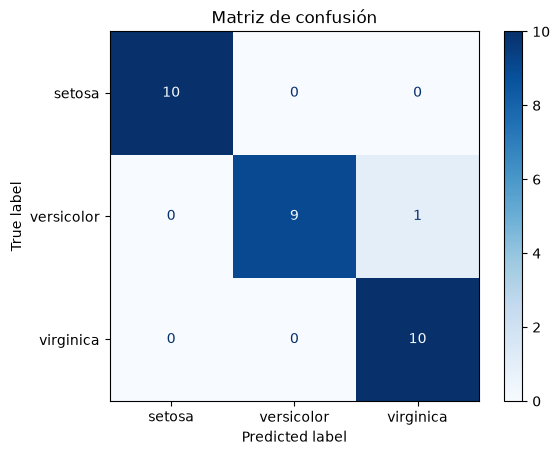

In [33]:
# Matriz de confusion
cm = confusion_matrix (y_test, prediccion, labels = modelo.classes_)
grafica = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels= modelo.classes_,
)
grafica.plot(cmap='Blues')
plt.title("Matriz de confusión")
plt.show()

In [34]:
# Importancia de las variables
importancias = pd.Series(
    modelo.feature_importances_,
    index= iris.feature_names
)
importancias = importancias.sort_values(ascending=False)

Importancia de cada variable predictora
petal length (cm)    0.579077
petal width (cm)     0.420923
sepal length (cm)    0.000000
sepal width (cm)     0.000000
dtype: float64


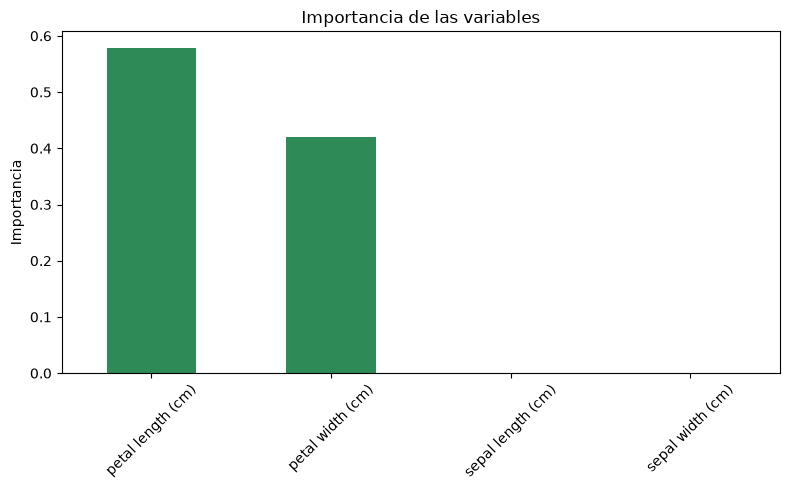

In [35]:
print("Importancia de cada variable predictora")
print(importancias)
#Grafica de Barras
plt.figure(figsize=(8,5))
importancias.plot(
    kind="bar",
    color="seagreen"
)
plt.title("Importancia de las variables")
plt.ylabel("Importancia")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()